# Import a Biacore Cycle/sample text export

Import **`biacore_cycle_sample.tsv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses the small file committed with the repository;
it does not download data or fit a model.

**Data origin:** [Duke TitrationAnalysis T200 example](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Example%20T200%20Chip%201%20Channel%202.txt). TitrationAnalysis tool, Kan Li and S Moses Dennison, Duke University. [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](../test_files/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/TitrationAnalysis-LICENSE).

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

# Works from the repository root, notebooks/, or docs/notebooks/.
cwd = Path.cwd().resolve()
repo_root = next(
    path for path in (cwd, *cwd.parents)
    if (path / "src" / "pykingenie").is_dir()
    and (path / "test_files" / "spr_exports").is_dir()
)
sys.path.insert(0, str(repo_root / "src"))
from pykingenie import SprTextExperiment, KineticsAnalyzer, plot_plate_info

plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
data_file = repo_root / "test_files" / "spr_exports" / "biacore_cycle_sample.tsv"
print("Input:", data_file.name)

Input: biacore_cycle_sample.tsv


## File layout and import settings

Tab-separated pairs such as `Cycle: 15  AE.A244  1.562_X` and its `_Y` column. The sparse excerpt retains two measured curves. The original Windows-1252 text was converted to UTF-8 for this fixture.

These text exports do not establish injection-event timing. The boundaries
below are **illustrative API settings**, not verified experimental events.
Replace them with your experiment's actual boundaries before kinetic analysis.
Both boundaries are seconds on the exported time axis. Association uses
`[association_start, association_end)`; dissociation starts at `association_end`.
There may be no baseline points before `association_start`.

The trailing `1.562` and `3.125` values are preserved as concentration labels, but no molar unit is established. Other columns in the full source include mass-unit labels; none are automatically treated as µM.

The expected concentration warning is displayed explicitly below. The common
`sample_id="unassigned"` is a grouping placeholder, not a biological identity
recovered from the file.

In [2]:
association_start = 0.0   # illustrative; replace with actual timing
association_end = 300.0  # illustrative; replace with actual timing

experiment = SprTextExperiment("biacore_cycle_sample")
with warnings.catch_warnings(record=True) as messages:
    warnings.simplefilter("always", UserWarning)
    experiment.read_file(
        data_file,
        association_start=association_start,
        association_end=association_end,
        decimal='.',
        time_unit="s",
        sample_id="unassigned",
    )
for message in messages:
    print(message.message)
print(f"Imported {experiment.no_sensors} measured curves; {experiment.no_steps} API phases.")
assert experiment.traces_loaded and experiment.no_sensors == 2

Some analyte concentrations are unavailable or have no unit. Provide concentrations or edit ligand_conc_df before fitting.
Imported 2 measured curves; 3 API phases.


## Available curve information

Each measured curve becomes a sensor in the experiment object. Its complete
original label remains in `sensor_names`. The following table extracts only
the header/row-label fields present in this specific example file.

In [3]:
curve_ids = [f"Curve {i + 1}" for i in range(experiment.no_sensors)]
labels = pd.Series(experiment.sensor_names, name="Exported label")
header_info = labels.str.extract('Cycle:\\s*(?P<Cycle>\\d+)\\s+(?P<Sample_label>\\S+)\\s+(?P<Concentration_label>.+)$')
header_info.insert(0, "Curve", curve_ids)
display(header_info)
display(labels.to_frame())

,Curve,Cycle,Sample_label,Concentration_label
0,Curve 1,15,AE.A244,1.562
1,Curve 2,16,AE.A244,3.125


,Exported label
0,Cycle: 15 AE.A244 1.562
1,Cycle: 16 AE.A244 3.125


## Concentration metadata

`NaN` means a molar concentration is unavailable, not zero concentration.
Before fitting, supply your verified values through `concentrations` and
`concentration_unit` at import, or update `ligand_conc_df`. A list follows the
measured-curve order; a mapping can use full exported curve labels as keys.

In [4]:
concentration_info = experiment.ligand_conc_df.copy()
concentration_info.insert(0, "Curve", curve_ids)
display(concentration_info[["Curve", "Concentration_micromolar", "SampleID"]])
assert concentration_info["Concentration_micromolar"].isna().all()

,Curve,Concentration_micromolar,SampleID
0,Curve 1,NaN,unassigned
1,Curve 2,NaN,unassigned


## Plate information, when available

Cycle numbers and the `AE.A244` sample label do not establish plate coordinates. No plate layout is present in this text export.

The conditional cell below uses `plot_plate_info` only when the experiment
actually contains the required plate metadata. It prints a message for this
file rather than assigning artificial well positions.

In [5]:
analyzer = KineticsAnalyzer()
analyzer.add_experiment(experiment, experiment.name)
plate_fields = (
    "sample_row", "sample_column", "sample_type", "sample_id", "sample_conc_labeled"
)
have_plate_info = all(
    getattr(experiment, field) is not None
    and len(getattr(experiment, field)) > 0
    for field in plate_fields
)
if have_plate_info:
    display(pd.DataFrame({field: getattr(experiment, field) for field in plate_fields}))
    plot_plate_info(analyzer, experiment.name).show()
else:
    print("No plate-well coordinates are available in this export; no plate plot is created.")

No plate-well coordinates are available in this export; no plate plot is created.


## Imported sensorgrams

Join the API phases back together for plotting on each curve's original time
grid. No time alignment or signal correction is applied. Markers show the
retained observations; short legend labels refer to the tables above.

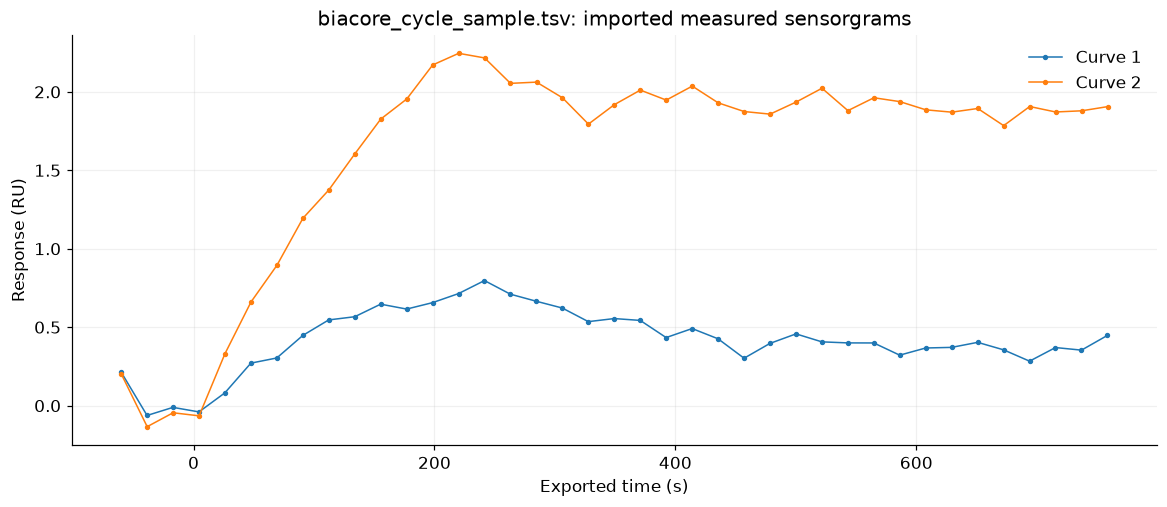

In [6]:
fig, ax = plt.subplots(figsize=(10.5, 4.5), constrained_layout=True)
for i, curve in enumerate(curve_ids):
    time = np.concatenate(experiment.xs[i])
    response = np.concatenate(experiment.ys[i])
    ax.plot(time, response, "o-", markersize=2.5, linewidth=1, label=curve)
ax.set(title="biacore_cycle_sample.tsv: imported measured sensorgrams",
       xlabel="Exported time (s)", ylabel="Response (RU)")
ax.legend(frameon=False)
ax.grid(alpha=0.18)
plt.show()

## Check the retained points and API partitions

The original times remain in `xs`; `ys` contains the corresponding measured
responses. The phase counts below reflect the illustrative boundaries above,
not injection events detected from the signal.

In [7]:
imported_points = pd.DataFrame([
    {
        "Curve": curve_ids[i],
        "Baseline points": len(experiment.xs[i][0]),
        "Association points": len(experiment.xs[i][1]),
        "Dissociation points": len(experiment.xs[i][2]),
        "Total points": sum(len(step) for step in experiment.xs[i]),
        "First exported time (s)": np.concatenate(experiment.xs[i])[0],
        "Last exported time (s)": np.concatenate(experiment.xs[i])[-1],
    }
    for i in range(experiment.no_sensors)
])
display(imported_points)
display(experiment.df_steps[["Name", "Type", "Start"]])

,Curve,Baseline points,Association points,Dissociation points,Total points,First exported time (s),Last exported time (s)
0,Curve 1,3,14,22,39,-60.06,758.64
1,Curve 2,3,14,22,39,-59.96,758.74


,Name,Type,Start
0,Baseline,BASELINE,-60.06
1,Association,ASSOC,0.00
2,Dissociation,DISASSOC,300.00


The independent-grid timestamps are retained for each cycle. This sparse excerpt is for file import and visualization; it does not establish injection timing or provide a dataset for reliable kinetic parameter estimation.